# Mideterm 3 assigment 1
### author: Filippo Alessandro Sandoval Villarreal mat: 596689

In this assignment, I will compare the performance of two types of denoising autoencoders: one built using convolutional layers and the other using only dense layers. The two denoising autoencoders will be compared using the same metrics.

In the cell below, I proceed with retrieving the data from a Kaggle dataset.

In [1]:
from tensorflow.keras.datasets import cifar10
(train_data_clean, train_labels), (test_data_clean, test_labels) = cifar10.load_data()


### Preprocessing
In the cells below, I begin with preprocessing the data. In particular, I have written three functions:

* **preprocess**: This function normalizes the image bytes to a range between 0 and 1.

* **noise**: This function adds Gaussian noise to the preprocessed image. The Gaussian distribution has a standard deviation of 0.3 and a mean of 0. The clip method ensures that the pixel values of the noisy images remain within the valid range of [0, 1].

* **display_cifar**: This function displays five images without noise and five images with noise, in order to visualize the difference between the two.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from keras import layers
from keras.datasets import mnist
from keras.models import Model


def preprocess(array):
    array = array.astype("float32") / 255.
    return array


def noise(array):
    
    noise_factor = 0.4
    noisy_array = array + noise_factor * np.random.normal(
        loc=0.0, scale=0.3, size=array.shape
    )

    return np.clip(noisy_array, 0.0, 1.0)


def display_cifar(array1, array2):
    n = 10
    indices = np.random.randint(len(array1), size=n)
    images1 = array1[indices]
    images2 = array2[indices]

    plt.figure(figsize=(20, 4))
    for i, (image1, image2) in enumerate(zip(images1, images2)):
        # Visualizza l'immagine originale
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(image1)  
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

        # Visualizza l'immagine con rumore
        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(image2)
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)

    plt.show()

In the cell below, I apply the functions I wrote in the cell above and display the results.

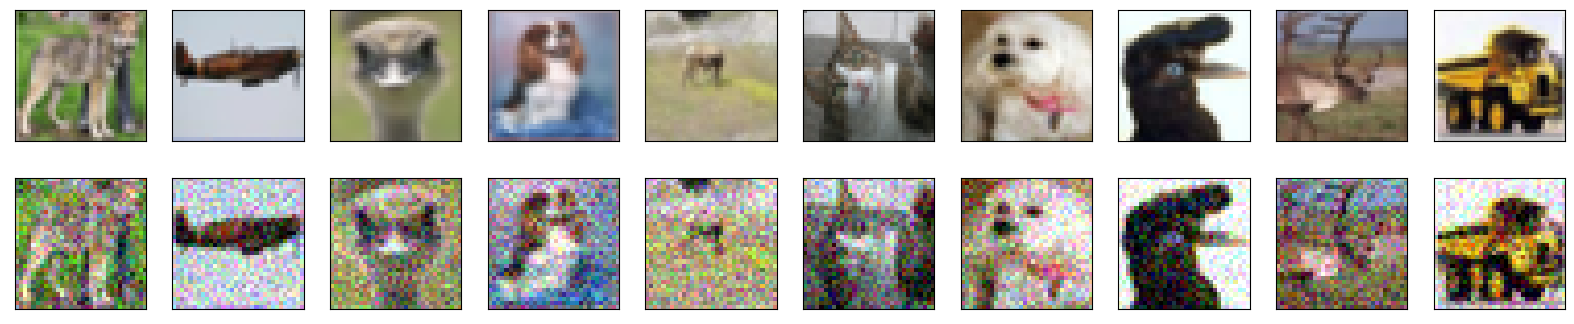

In [3]:
#(train_data, _), (test_data, _) = mnist.load_data()

# Normalize and reshape the data
train_data_clean = preprocess(train_data_clean)
test_data_clean = preprocess(test_data_clean)

# Create a copy of the data with added noise
noisy_train_data = noise(train_data_clean)
noisy_test_data = noise(test_data_clean)

# Display the train data and a version of it with added noise
display_cifar(train_data_clean, noisy_train_data)



### Evaluation metric
In order to evaluate the performance of the two models, I use the SSIM metric. This metric assesses the structural similarity between two images by considering luminance, contrast, and structure. It is often used to evaluate the perceived quality of an image compared to a reference image. In this way, I aim to measure the similarity between the original image and the denoised one produced by the denoising autoencoder.
The SSIM metric is formulated as follows:

$$
\text{SSIM}(x, y) = \frac{(2\mu_x\mu_y + c_1)(2\sigma_{xy} + c_2)}{(\mu_x^2 + \mu_y^2 + c_1)(\sigma_x^2 + \sigma_y^2 + c_2)}
$$
where:
* $\mu_x$ is the average of $x$.
* $\mu_y$ is the average of $y$.
* $\sigma_x^2$ is the variance of $x$.
* $\sigma_y^2$ is the variance of $y$.
* $\sigma_{xy}$ is the covariance of $x$ and $y$.
* $c_1 = (k_1 L)^2$ and $c_2 = (k_2 L)^2$ are small constants used to stabilize the division. $L$ is the dynamic range of the pixel values, and $k_1$ and $k_2$ are typically small values.


In [ ]:
import tensorflow as tf
import tensorflow.keras.backend as K

def ssim(y_true, y_pred):
   
    return tf.image.ssim(y_true, y_pred, max_val=1.0) # Assuming pixel values are scaled to [0, 1]

### Denoise autoencoder with convolutional layers

The first model I decided to implement was the denoising autoencoder with convolutional layers. In this architecture, the input layer is designed to receive an image with a height of 32 pixels, width of 32 pixels, and 3 color channels.

The encoder consists of three convolutional layers. The first layer has 64 filters, with each filter learning to detect a specific pattern in the input image (resulting in 64 feature maps). All convolutional layers use ReLU as the activation function and have padding set to 'same', so the spatial dimensions (height and width) of the output remain the same as the input. The filters are 5x5 in size and perform the convolution operation over the image.

Each convolutional layer is followed by a batch normalization layer, a technique used to stabilize and accelerate training. Batch normalization normalizes the activations of the previous layer across each batch of training data, which helps reduce internal covariate shift.

After each batch normalization, there is a max pooling operation that performs downsampling. Specifically, it selects the maximum value from each 2x2 window in the input feature maps. This reduces the spatial dimensions (both height and width are halved), making the network more robust to small translations in the input. Max pooling is also configured with padding set to 'same' to ensure consistent behavior even when the input dimensions are odd.

The encoder has three such blocks, with the number of filters increasing from 64 in the first layer to 256 in the last.

The decoder takes the compressed representation from the encoder and progressively upsamples it while reducing the number of feature maps, aiming to reconstruct the original input image. It mirrors the encoder structure, with three transposed convolutional (deconvolutional) layers. The number of filters decreases from 256 to 64. Each layer uses ReLU activation, 'same' padding, and 5x5 kernel size, consistent with the encoder.

A key difference in the decoder is the use of strides set to 2 in each transposed convolution. This stride value is crucial for upsampling, as a stride of 2 effectively doubles the spatial dimensions of the input. Each input pixel produces a 2x2 block in the output.

The final convolutional layer is slightly different. It has 3 filters to reconstruct the 3 RGB color channels of the image. It still uses a 5x5 kernel size and 'same' padding to maintain the original image dimensions, but its activation function is sigmoid. The sigmoid activation function is commonly used in autoencoders when the input images are normalized to the [0, 1] range, as it outputs values in that same range.

Finally, I compiled the model using the Adam optimizer, mean squared error as the loss function (suitable for this task as explained here: https://www.scirp.org/journal/paperinformation?paperid=90911), and SSIM as the evaluation metric, as discussed in the cell above.

In [6]:
input = layers.Input(shape=(32, 32, 3))

# Encoder
x = layers.Conv2D(64, (5, 5), activation="relu", padding="same")(input)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
x = layers.Conv2D(128, (5, 5), activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
x = layers.Conv2D(256, (5, 5), activation="relu", padding="same")(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D((2, 2), padding="same")(x)
#si partiva con 32 ora con 64 
# Decoder
x = layers.Conv2DTranspose(256, (5, 5), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(128, (5, 5), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2DTranspose(64, (5, 5), strides=2, activation="relu", padding="same")(x)
x = layers.Conv2D(3, (5, 5), activation="sigmoid", padding="same")(x)



# Autoencoder
autoencoder = Model(input, x)
autoencoder.compile(optimizer="adam", loss="mean_squared_error", metrics=[ssim])
autoencoder.summary()


Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d_4 (Conv2D)           (None, 32, 32, 64)        4864      
                                                                 
 batch_normalization_3 (Bat  (None, 32, 32, 64)        256       
 chNormalization)                                                
                                                                 
 max_pooling2d_3 (MaxPoolin  (None, 16, 16, 64)        0         
 g2D)                                                            
                                                                 
 conv2d_5 (Conv2D)           (None, 16, 16, 128)       204928    
                                                                 
 batch_normalization_4 (Bat  (None, 16, 16, 128)       512

In the cell below, I proceed with splitting the dataset into training, validation, and test sets using the hold-out method.

In [5]:
from sklearn.model_selection import train_test_split

train_data_clean, val_data_clean, _, _ = train_test_split(
    train_data_clean, train_labels, test_size=0.2, random_state=42
)
noisy_train_data, noisy_val_data, _, _ = train_test_split(
    noisy_train_data, train_labels, test_size=0.2, random_state=42
)

In the cell below, I train the model using early stopping to prevent overfitting. The model is trained for 25 epochs with a batch size of 128.

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',  # Metric to monitor (validation loss)
    patience=3,         # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restore model weights from the epoch with the best value of the monitored metric.
)

history = autoencoder.fit(
    x=noisy_train_data,
    y=train_data_clean,
    epochs=25,
    batch_size=128,
    shuffle=True,
    validation_data=(noisy_val_data, val_data_clean),
    callbacks=[early_stopping]
)


Epoch 1/25


313/313 [==============================] - 287s 909ms/step - loss: 0.0117 - ssim: 0.5687 - val_loss: 0.0140 - val_ssim: 0.4913
Epoch 2/25
313/313 [==============================] - 275s 879ms/step - loss: 0.0056 - ssim: 0.7426 - val_loss: 0.0076 - val_ssim: 0.7509
Epoch 3/25
313/313 [==============================] - 256s 817ms/step - loss: 0.0047 - ssim: 0.7816 - val_loss: 0.0058 - val_ssim: 0.7873
Epoch 4/25
313/313 [==============================] - 268s 856ms/step - loss: 0.0041 - ssim: 0.8024 - val_loss: 0.0038 - val_ssim: 0.8079
Epoch 5/25
313/313 [==============================] - 243s 777ms/step - loss: 0.0039 - ssim: 0.8137 - val_loss: 0.0043 - val_ssim: 0.8070
Epoch 6/25
313/313 [==============================] - 243s 777ms/step - loss: 0.0037 - ssim: 0.8228 - val_loss: 0.0035 - val_ssim: 0.8317
Epoch 7/25
313/313 [==============================] - 245s 783ms/step - loss: 0.0034 - ssim: 0.8315 - val_loss: 0.0036 - val_ssim: 0.8343
Epoch 8/25
313/313 [============

In [ ]:
autoencoder.save('autoencoder_conv_best')

INFO:tensorflow:Assets written to: autoencoder_conv_best\assets


INFO:tensorflow:Assets written to: autoencoder_conv_best\assets


The autoencoder with convolutional layers underwent an extensive model selection process on the validation set. Different kernel sizes (5x5, 7x7, and 3x3) were tested, as well as various numbers of filters—for example, 256 or 32. Several configurations were also explored, including deeper networks. However, none of these alternatives outperformed the model reported in the cell above.
Some of the SSIM scores obtained from these earlier models were: 0.8278, 0.7624, and 0.8431. A deeper search cuold be performed

1/1 [==============================] - 0s 200ms/step


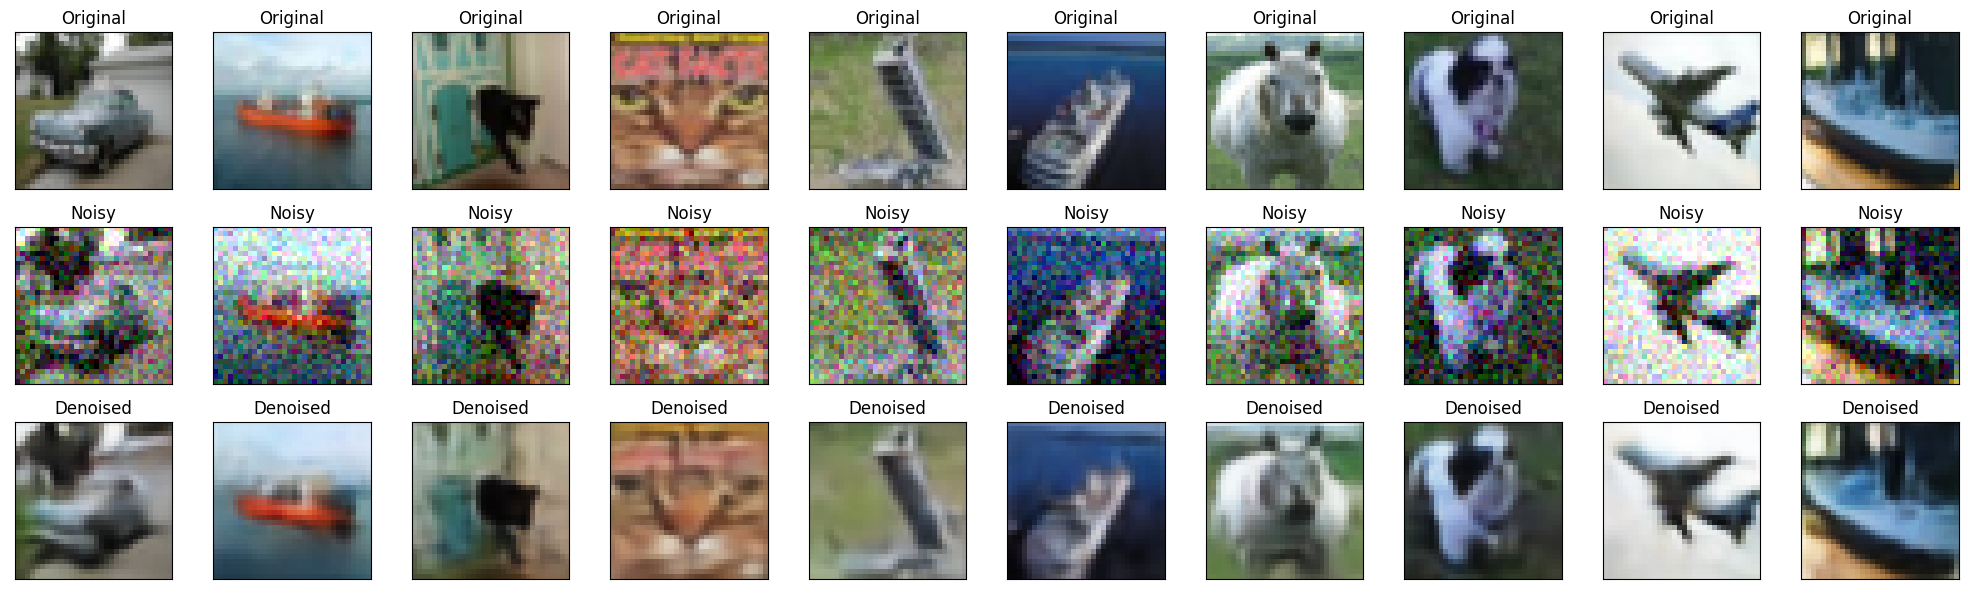

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = 10
indices = np.random.choice(len(val_data_clean), size=n, replace=False)
original_images = val_data_clean[indices]
noisy_images = noisy_val_data[indices]

decoded_images = autoencoder.predict(noisy_images)

plt.figure(figsize=(20, 6))
for i in range(n):
    # Immagine originale
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(original_images[i])
    plt.title("Original")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine con rumore
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(noisy_images[i])
    plt.title("Noisy")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine de-noise
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_images[i])
    plt.title("Denoised")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

In the picture above, we can see the reconstruction on the validation set produced by the denoising autoencoder using convolutional layers. The results are quite good, except for some minor details, and they correspond to an SSIM score of 0.8544.

### Autoencoder using dense layers

Following the structure of the denoising autoencoder with convolutional layers, I built a similar model using only dense layers. The new autoencoder takes flattened images as input. For example, a 32x32 pixel RGB image (with 3 color channels) is flattened into a single vector of 3072 values.

The encoder consists of several dense (fully connected) layers that progressively reduce the dimensionality of the input, compressing the image data into a lower-dimensional encoded representation. ReLU activation functions are used to introduce non-linearity, allowing the network to learn complex patterns.

The decoder mirrors the encoder in reverse. It takes the compressed representation and uses a series of dense layers to expand the data back to the original input size. A sigmoid activation function is applied in the final layer to ensure that output values fall within the range [0, 1], suitable for representing pixel intensities.

Finally, an output layer reconstructs the image, which is then reshaped to match the original image dimensions (32x32x3).

I compiled the model using the same metric as the convolutional autoencoder (SSIM) and the same loss function (mean squared error).

In [ ]:
from tensorflow.keras import layers, Model

# Input shape: 32x32x3 = 3072 features
input_shape = 32 * 32 * 3
input_img = layers.Input(shape=(input_shape,))

# Encoder (Dense Layers mirroring convolutional structure)
#encoded = layers.Dense(1024, activation='selu')(input_img) 
#encoded = layers.Dense(512, activation='selu')(encoded)
encoded = layers.Dense(2048, activation='relu')(input_img)
encoded = layers.Dense(1024, activation='relu')(encoded)  
encoded = layers.Dense(512, activation='relu')(encoded)  
#encoded = layers.Dense(256, activation='relu')(encoded)
# Decoder (Dense Layers mirroring convolutional transpose structure)

#decoded = layers.Dense(64, activation='relu')(encoded)
#decoded = layers.Dense(124, activation='relu')(decoded) 
#decoded = layers.Dense(256, activation='relu')(encoded) 

decoded = layers.Dense(1024, activation='relu')(encoded)
decoded = layers.Dense(2048, activation='relu')(decoded)
#decoded = layers.Dense(256, activation='relu')(decoded)
decoded = layers.Dense(input_shape, activation='sigmoid')(decoded) # Output shape

output_reshaped = layers.Reshape((32, 32, 3))(decoded)

# Autoencoder
autoencoder_dense_mirrored = Model(input_img, output_reshaped)
# Autoencoder
#autoencoder_dense_mirrored = Model(input_img, decoded)

# Compile the autoencoder
autoencoder_dense_mirrored.compile(optimizer='adam', loss='mean_squared_error',metrics=[ssim])
autoencoder_dense_mirrored.summary()



Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 3072)]            0         
                                                                 
 dense (Dense)               (None, 2048)              6293504   
                                                                 
 dense_1 (Dense)             (None, 1024)              2098176   
                                                                 
 dense_2 (Dense)             (None, 512)               524800    
                                                                 
 dense_3 (Dense)             (None, 1024)              525312    
                                                                 
 dense_4 (Dense)             (None, 2048)              2099200   
                                                                 
 dense_5 (Dense)             (None, 3072)              6294

In the cell below, I proceed to flatten the data in order to feed it as input to the neural network.

In [7]:
train_data_clean_flat = train_data_clean.reshape(-1, 32 * 32 * 3)
noisy_train_data_flat = noisy_train_data.reshape(-1, 32 * 32 * 3)
val_data_clean_flate = val_data_clean.reshape(-1, 32 * 32 * 3)
noisy_val_data_flat = noisy_val_data.reshape(-1, 32 * 32 * 3)


As with the autoencoder using convolutional layers, I apply early stopping with the same patience. However, in this case, the model is trained for up to 100 epochs with a batch size of 128.

In [8]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',  # Metric to monitor (validation loss)
    patience=5,         # Number of epochs with no improvement after which training will be stopped
    restore_best_weights=True  # Restore model weights from the epoch with the best value of the monitored metric.
)

history = autoencoder_dense_mirrored.fit(
    x=noisy_train_data_flat,
    y=train_data_clean,
    epochs=100,
    batch_size=128,
    shuffle=True,
    validation_data=(noisy_val_data_flat, val_data_clean),
    callbacks=[early_stopping]
)

Epoch 1/100


313/313 [==============================] - 93s 279ms/step - loss: 0.0358 - ssim: 0.1985 - val_loss: 0.0253 - val_ssim: 0.2472
Epoch 2/100
313/313 [==============================] - 84s 268ms/step - loss: 0.0231 - ssim: 0.2773 - val_loss: 0.0220 - val_ssim: 0.2927
Epoch 3/100
313/313 [==============================] - 623s 2s/step - loss: 0.0207 - ssim: 0.3107 - val_loss: 0.0196 - val_ssim: 0.3318
Epoch 4/100
313/313 [==============================] - 46s 148ms/step - loss: 0.0180 - ssim: 0.3576 - val_loss: 0.0174 - val_ssim: 0.3765
Epoch 5/100
313/313 [==============================] - 48s 154ms/step - loss: 0.0165 - ssim: 0.3862 - val_loss: 0.0180 - val_ssim: 0.3805
Epoch 6/100
313/313 [==============================] - 43s 137ms/step - loss: 0.0157 - ssim: 0.4017 - val_loss: 0.0153 - val_ssim: 0.4090
Epoch 7/100
313/313 [==============================] - 43s 137ms/step - loss: 0.0149 - ssim: 0.4209 - val_loss: 0.0148 - val_ssim: 0.4252
Epoch 8/100
313/313 [=============

In [9]:
autoencoder_dense_mirrored.save('autoencoder_dende_best')

INFO:tensorflow:Assets written to: autoencoder_dende_best\assets


INFO:tensorflow:Assets written to: autoencoder_dende_best\assets


The autoencoder with dense layers underwent extensive model selection on the validation set. Various values for the number of neurons and activation functions were tested (for example, layer sizes of 2048 neurons and activation functions such as sigmoid, SELU, and ELU). Deeper models were also explored, including the use of dropout techniques to control overfitting. However, the performance did not improve significantly and the model in the cell above was the best.

A more thorough search of possible architectures and hyperparameters could be conducted to achieve better results.

1/1 [==============================] - 0s 66ms/step


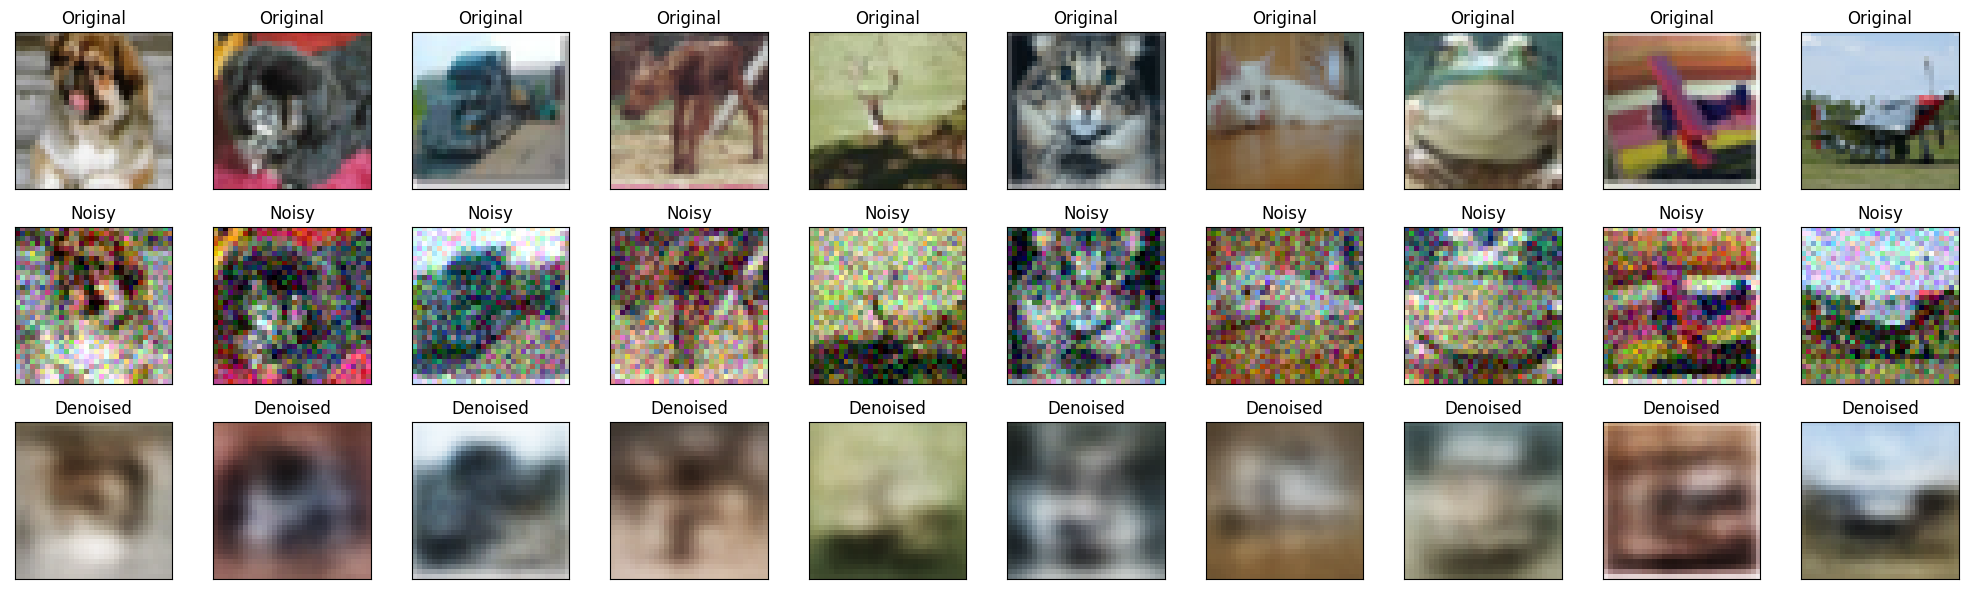

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


n = 10
indices = np.random.choice(len(val_data_clean_flate), size=n, replace=False)
original_images = val_data_clean_flate[indices]
noisy_images = noisy_val_data_flat[indices]


decoded_images = autoencoder_dense_mirrored.predict(noisy_images)
noisy_images = noisy_images.reshape(-1,32,32,3)
original_images = original_images.reshape(-1,32,32,3)

plt.figure(figsize=(20, 6))
for i in range(n):
    # Immagine originale
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(original_images[i])
    plt.title("Original")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine con rumore
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(noisy_images[i])
    plt.title("Noisy")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine de-noise
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_images[i])
    plt.title("Denoised")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

The cell above plots the results obtained from the reconstruction performed by the denoising autoencoder using only dense layers. The results are not as clear as those produced by the denoising autoencoder with convolutional layers. In particular, the model using only dense layers seems unable to capture all the details of the image, losing a significant amount of information.

### Evaluation and comparison of the two models

In this section, we will evaluate both models using the test set to compare their performances.

In [ ]:
from tensorflow.keras.models import load_model


model_path = 'autoencoder_conv_best'  


try:
    model = load_model(model_path,custom_objects={'ssim': ssim})
    print(f"Modello caricato con successo da {model_path}")
except Exception as e:
    print(f"Errore durante il caricamento del modello: {e}")
    exit()


Modello caricato con successo da autoencoder_conv_best


In the cell below, the SSIM and loss results on the test set are reported for the autoencoder with convolutional layers.

In [14]:
results = model.evaluate(noisy_test_data, test_data_clean,batch_size=128)
print(f"Test Loss (MSE): {results[0]:.4f}")
print(f"Test SSIM: {results[1]:.4f}")



79/79 [==============================] - 15s 188ms/step - loss: 0.0028 - ssim: 0.8520
Test Loss (MSE): 0.0028
Test SSIM: 0.8520


1/1 [==============================] - 0s 217ms/step


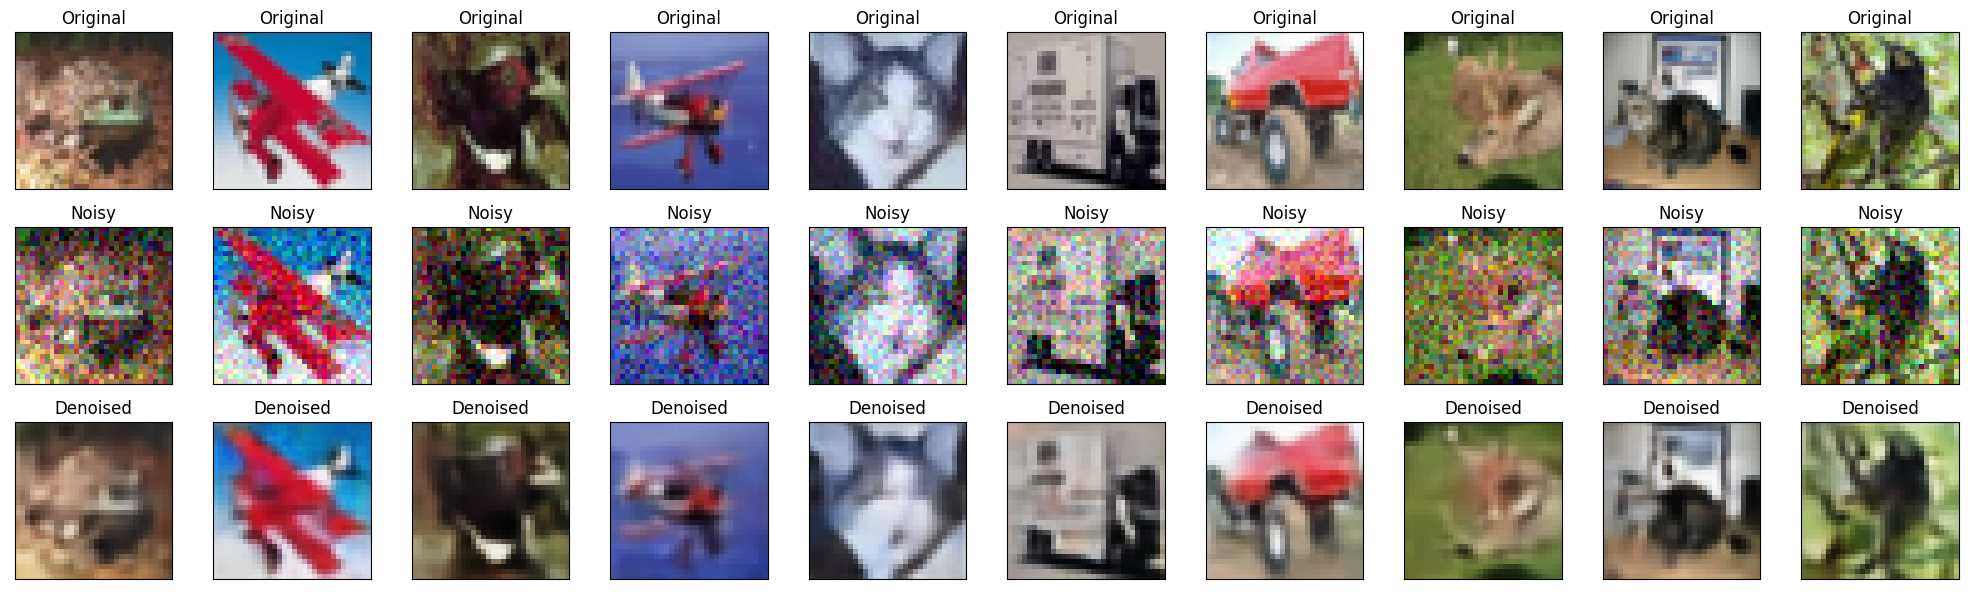

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


n = 10
indices = np.random.choice(len(test_data_clean), size=n, replace=False)
original_images = test_data_clean[indices]
noisy_images = noisy_test_data[indices]


decoded_images = model.predict(noisy_images)

# 3. Visualizza le triple
plt.figure(figsize=(20, 6))
for i in range(n):
    # Immagine originale
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(original_images[i])
    plt.title("Original")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine con rumore
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(noisy_images[i])
    plt.title("Noisy")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine de-noise
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_images[i])
    plt.title("Denoised")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

The picture above shows the denoising results on the test set images using the denoising autoencoder with convolutional layers.

In [ ]:
from tensorflow.keras.models import load_model

model_path = 'autoencoder_dende_best'  

try:
    model_dense = load_model(model_path,custom_objects={'ssim': ssim})
    print(f"Modello caricato con successo da {model_path}")
except Exception as e:
    print(f"Errore durante il caricamento del modello: {e}")
    exit()


Modello caricato con successo da autoencoder_dende_best


In the cell below, the SSIM and loss results on the test set are reported for the autoencoder with dense layers.

In [12]:
noisy_test_data_flat = noisy_test_data.reshape(-1, 32 * 32 * 3)
results = model_dense.evaluate(noisy_test_data_flat, test_data_clean,batch_size=128)
print(f"Test Loss (MSE): {results[0]:.4f}")
print(f"Test SSIM: {results[1]:.4f}")


79/79 [==============================] - 2s 23ms/step - loss: 0.0099 - ssim: 0.5802
Test Loss (MSE): 0.0099
Test SSIM: 0.5802


1/1 [==============================] - 0s 29ms/step


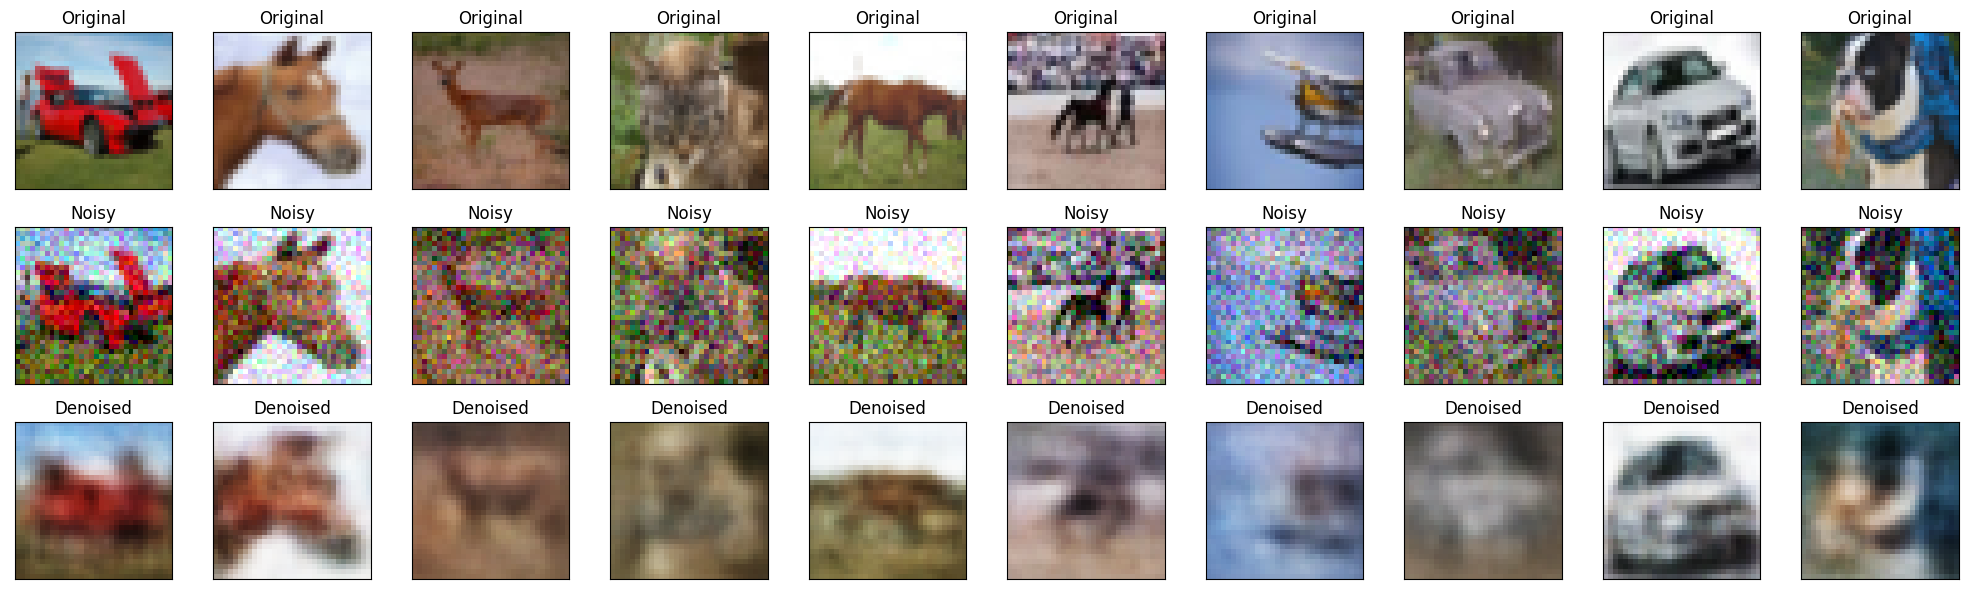

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


n = 10
indices = np.random.choice(len(test_data_clean), size=n, replace=False)
original_images = test_data_clean[indices]
noisy_images = noisy_test_data_flat[indices]


decoded_images = model_dense.predict(noisy_images)
noisy_images = noisy_images.reshape(-1,32,32,3)


plt.figure(figsize=(20, 6))
for i in range(n):
    # Immagine originale
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(original_images[i])
    plt.title("Original")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine con rumore
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(noisy_images[i])
    plt.title("Noisy")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Immagine de-noise
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded_images[i])
    plt.title("Denoised")
    #plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

The picture above shows the denoising results on the test set images using the denoising autoencoder with dense layers.

As we can see from the performance on the test set, the denoising autoencoder with convolutional layers performs significantly better than the one composed only of dense layers.

### Conclusions

As we can observe from the performances of the two models, the autoencoder with convolutional layers performs better than the one with only dense layers. Several factors can explain this behavior, particularly related to the nature of convolutional and dense layers.

Convolutional layers use filters that slide over the image, capturing local patterns such as edges, textures, and shapes. This preserves the 2D spatial relationships between pixels, which is crucial for understanding images. Dense layers, on the other hand, flatten the image and apply linear operations, which destroys the 2D spatial relationships between pixels, making it harder to learn the structure of objects and scenes.

This architectural difference not only means that dense layers have a higher number of parameters, making them harder to train and more prone to overfitting, but it also negatively impacts the denoising task. Since dense layers lose spatial relationships, they cannot effectively capture information from neighboring pixels.

This explains why the SSIM metric, which measures structural similarity between reconstructed and original images, has a much lower value for the autoencoder with dense layers, highlighting the loss of important information when using dense layers alone.